# GEOM7001 Mine Rehabilitation Project

## Study Area

**Study site:** New Acland Mine, Queensland

**Coordinate system:** GDA2020 / MGA Zone 56 (EPSG:7856)

This study investigates vegetation recovery within rehabilitated areas of the New Acland Mine using multi-temporal Sentinel-1 and Sentinel-2 imagery.

### 1. Setup and packages & define the study area
Import packages and connect to dea datacutes

The bounding rectangle is used to query satellite imagery from DEA.

The exact irregular study-site polygon will later be used to mask pixels outside the study area.

The study area extent from ArcGIS pro
Coordinate system: GDA2020 / MGA Zone 56 EPSG: 7856

In [1]:
%matplotlib inline

import json
import datacube
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import numpy as np
import rioxarray as rxr

from shapely.geometry import shape
from dea_tools.datahandling import load_ard
from dea_tools.plotting import rgb

# Connect to DEA
dc = datacube.Datacube(app="GEOM7001_mine_rehabilitation")

# Load study-area polygon
with open("Study_site_output.json", "r") as f:
    study_json = json.load(f)

geometry = shape(study_json["features"][0]["geometry"])

study_area = gpd.GeoDataFrame(
    geometry=[geometry],
    crs="EPSG:7856"
)

# Get bounding box automatically
xmin, ymin, xmax, ymax = study_area.total_bounds

x = (xmin, xmax)
y = (ymin, ymax)

print("Area:", study_area.geometry.area.sum() / 1_000_000, "km²")
print("X:", x)
print("Y:", y)

Area: 25.328987062379927 km²
X: (np.float64(370057.7240000004), np.float64(375439.63129999954))
Y: (np.float64(6977342.7855), np.float64(6983807.8862))


### 2.  Check Sentinel-2 availability



In [2]:
time_range = ("2015-01-01", "2025-12-31")

query = {
    "x": x,
    "y": y,
    "crs": "EPSG:7856",
    "time": time_range
}

products = {
    "Sentinel-2A": "ga_s2am_ard_3",
    "Sentinel-2B": "ga_s2bm_ard_3",
    "Sentinel-2C": "ga_s2cm_ard_3"
}

for name, product in products.items():

    datasets = dc.find_datasets(
        product=product,
        **query
    )

    dates = pd.to_datetime(
        [d.center_time for d in datasets],
        utc=True
    )

    print(
        name,
        "| observations:", len(dates),
        "|", dates.min().date(),
        "to", dates.max().date()
    )

Sentinel-2A | observations: 340 | 2015-10-23 to 2025-12-31
Sentinel-2B | observations: 306 | 2017-07-09 to 2025-12-24
Sentinel-2C | observations: 35 | 2025-01-23 to 2025-12-29


### 3. Load Sentinel-2 Image

In [3]:
s2 = load_ard(
    dc=dc,

    products=[
        "ga_s2am_ard_3",
        "ga_s2bm_ard_3",
        "ga_s2cm_ard_3"
    ],

    x=x,
    y=y,
    crs="EPSG:7856",
    time=("2024-01-01", "2024-12-31"),

    measurements=[
        "nbart_blue",
        "nbart_green",
        "nbart_red",
        "nbart_red_edge_1",
        "nbart_red_edge_2",
        "nbart_red_edge_3",
        "nbart_nir_1",
        "nbart_swir_2",
        "nbart_swir_3"
    ],

    output_crs="EPSG:7856",
    resolution=(-20, 20),

    cloud_mask="s2cloudless",
    min_gooddata=0.70,
    group_by="solar_day"
)

print(s2.sizes)

Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless


/env/lib/python3.10/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Filtering to 45 out of 73 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 45 time steps
Frozen({'time': 45, 'y': 324, 'x': 270})


### 4. Plot the polygon 

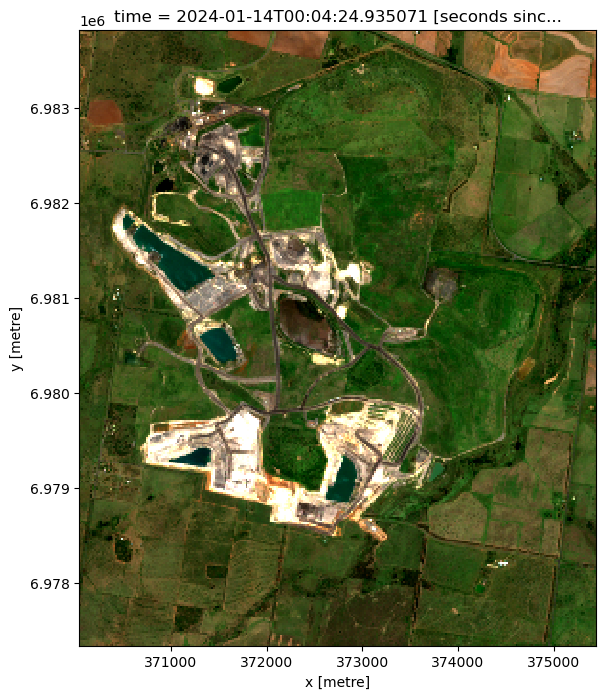

In [4]:
rgb(
    s2,
    bands=["nbart_red", "nbart_green", "nbart_blue"],
    index=0,
    size=8
)

## 5. Mask to Exact Study Area

Sentinel-2 imagery was initially loaded using the rectangular bounding extent of the study area. The exact ArcGIS study-site polygon is now used to mask pixels outside the study area.from rasterio.features import geometry_mask
from affine import Affine


In [5]:
from rasterio.features import geometry_mask
from affine import Affine

# Get spatial resolution
x_res = float(s2.x[1] - s2.x[0])
y_res = float(s2.y[1] - s2.y[0])

# Construct raster transform
transform = Affine(
    x_res, 0, float(s2.x[0] - x_res / 2),
    0, y_res, float(s2.y[0] - y_res / 2)
)

# Create mask from exact study-area polygon
mask = geometry_mask(
    [study_area.geometry.iloc[0].__geo_interface__],
    out_shape=(s2.sizes["y"], s2.sizes["x"]),
    transform=transform,
    invert=True
)

# Convert to xarray
mask = xr.DataArray(
    mask,
    coords={"y": s2.y, "x": s2.x},
    dims=("y", "x")
)

# Mask pixels outside study area
s2_masked = s2.where(mask)

s2_masked

<xarray.Dataset> Size: 142MB
Dimensions:           (time: 45, y: 324, x: 270)
Coordinates:
  * time              (time) datetime64[ns] 360B 2024-01-14T00:04:24.935071 ....
  * y                 (y) float64 3kB 6.984e+06 6.984e+06 ... 6.977e+06
  * x                 (x) float64 2kB 3.7e+05 3.701e+05 ... 3.754e+05 3.754e+05
    spatial_ref       int32 4B 7856
Data variables:
    nbart_blue        (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_green       (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_red         (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_red_edge_1  (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_red_edge_2  (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_red_edge_3  (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_nir_1       (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_swir_2      (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
    nbart_swir_3      (time, y, x) float32 16MB nan nan nan nan ... nan nan nan
Attributes:
    crs:           EPSG:7856
    grid_mapping:  spatial_ref

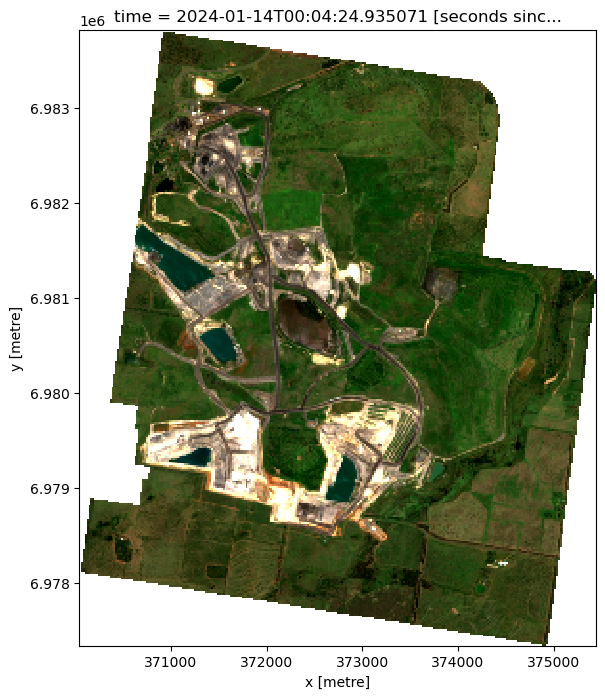

In [6]:
# Check masked study area

rgb(
    s2_masked,
    bands=["nbart_red", "nbart_green", "nbart_blue"],
    index=0,
    size=8
)

### 6. Calculate Vegetation Indices
Vegetation indices are calculated from the cloud-masked Sentinel-2 imagery to characterise vegetation condition within the rehabilitation study area.

In [7]:
# Convert scaled NBART values to reflectance
red = s2_masked.nbart_red / 10000
nir = s2_masked.nbart_nir_1 / 10000
blue = s2_masked.nbart_blue / 10000

# NDVI
ndvi = (nir - red) / (nir + red)

# EVI
evi = (
    2.5 * (nir - red) /
    (nir + 6 * red - 7.5 * blue + 1)
)

# Remove unrealistic values
ndvi = ndvi.where((ndvi >= -1) & (ndvi <= 1))
evi = evi.where((evi >= -1) & (evi <= 1))

s2_masked["NDVI"] = ndvi
s2_masked["EVI"] = evi

print(
    "NDVI range:",
    float(s2_masked.NDVI.min()),
    "to",
    float(s2_masked.NDVI.max())
)

print(
    "EVI range:",
    float(s2_masked.EVI.min()),
    "to",
    float(s2_masked.EVI.max())
)

NDVI range: -0.5820286273956299 to 0.910405695438385
EVI range: -0.21370968222618103 to 0.9548797607421875


NDRE range: -0.7455471158027649 to 0.7777777910232544


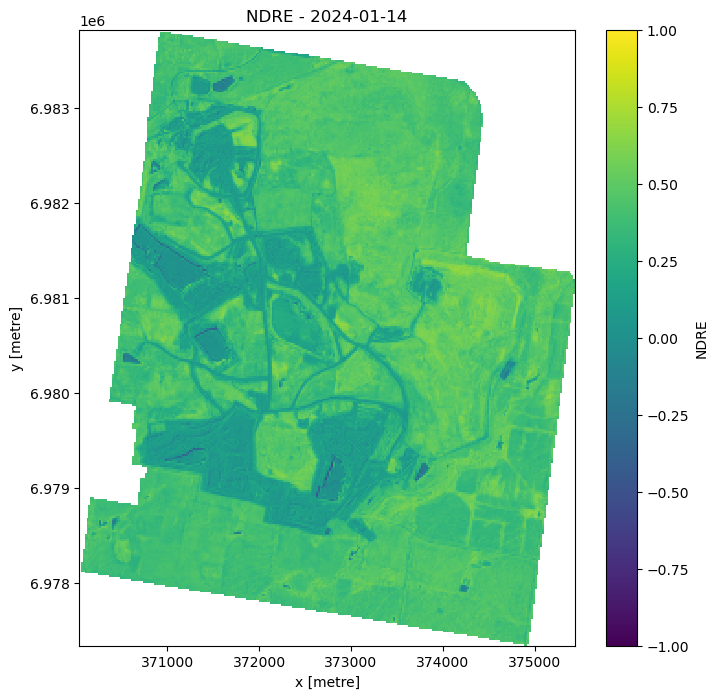

In [8]:
# NDRE (Normalized Difference Red Edge)

red_edge = s2_masked.nbart_red_edge_1 / 10000

ndre = (nir - red_edge) / (nir + red_edge)

# Remove unrealistic values
ndre = ndre.where((ndre >= -1) & (ndre <= 1))

s2_masked["NDRE"] = ndre

print(
    "NDRE range:",
    float(s2_masked.NDRE.min()),
    "to",
    float(s2_masked.NDRE.max())
)

s2_masked.NDRE.isel(time=0).plot(
    figsize=(8, 8),
    vmin=-1,
    vmax=1
)

plt.title(
    f"NDRE - {pd.to_datetime(s2_masked.time.values[0]).date()}"
)

plt.show()

### 7. Create Monthly Composites


In [9]:
# Create monthly median composites

s2_monthly = s2_masked[
    ["NDVI", "EVI", "NDRE"]
].resample(time="1MS").median()

s2_monthly

print("Number of monthly composites:", s2_monthly.sizes["time"])
print(s2_monthly.time.values)

Number of monthly composites: 12
['2024-01-01T00:00:00.000000000' '2024-02-01T00:00:00.000000000'
 '2024-03-01T00:00:00.000000000' '2024-04-01T00:00:00.000000000'
 '2024-05-01T00:00:00.000000000' '2024-06-01T00:00:00.000000000'
 '2024-07-01T00:00:00.000000000' '2024-08-01T00:00:00.000000000'
 '2024-09-01T00:00:00.000000000' '2024-10-01T00:00:00.000000000'
 '2024-11-01T00:00:00.000000000' '2024-12-01T00:00:00.000000000']


### 8. Check Monthly Data Availability

In [10]:
# Check valid pixel coverage for each monthly composite

for i in range(s2_monthly.sizes["time"]):
    
    month = pd.to_datetime(
        s2_monthly.time.values[i]
    ).strftime("%Y-%m")
    
    ndvi_month = s2_monthly.NDVI.isel(time=i)
    
    valid_pixels = ndvi_month.notnull().sum().item()
    total_pixels = ndvi_month.size
    
    valid_percent = valid_pixels / total_pixels * 100
    
    print(
        month,
        f"- Valid pixels: {valid_percent:.1f}%"
    )

2024-01 - Valid pixels: 72.4%
2024-02 - Valid pixels: 72.4%
2024-03 - Valid pixels: 72.4%
2024-04 - Valid pixels: 72.4%
2024-05 - Valid pixels: 72.4%
2024-06 - Valid pixels: 72.4%
2024-07 - Valid pixels: 72.4%
2024-08 - Valid pixels: 72.4%
2024-09 - Valid pixels: 72.4%
2024-10 - Valid pixels: 72.4%
2024-11 - Valid pixels: 72.4%
2024-12 - Valid pixels: 72.4%


In [11]:
# Number of pixels inside the study-area polygon
study_pixels = mask.sum().item()

print("Pixels inside study area:", study_pixels)

Pixels inside study area: 63323


In [12]:
# Summarise monthly Sentinel-2 data availability

records = []

for month, group in s2_masked.NDVI.resample(time="MS"):

    n_obs = group.sizes["time"]

    coverage = []

    for i in range(n_obs):
        valid_pixels = group.isel(time=i).notnull().sum().item()
        coverage.append(valid_pixels / study_pixels * 100)

    records.append({
        "Month": pd.to_datetime(month).strftime("%Y-%m"),
        "Observations": n_obs,
        "Mean valid coverage (%)": np.mean(coverage),
        "Minimum valid coverage (%)": np.min(coverage)
    })

monthly_availability = pd.DataFrame(records)

monthly_availability

,Month,Observations,Mean valid coverage (%),Minimum valid coverage (%)
0,2024-01,2,100.000000,100.000000
1,2024-02,3,98.780327,96.340982
2,2024-03,3,98.074949,96.377304
3,2024-04,5,86.770999,69.570298
4,2024-05,3,100.000000,100.000000
5,2024-06,4,97.473272,91.023799
6,2024-07,4,97.329564,94.280119
7,2024-08,5,97.973880,89.869400
8,2024-09,6,99.711005,98.266033
9,2024-10,4,90.186425,79.293464


In [13]:
# Check valid coverage BEFORE monthly compositing

print("Number of observations:", s2_masked.sizes["time"])
print()

for i in range(s2_masked.sizes["time"]):

    date = pd.to_datetime(
        s2_masked.time.values[i]
    ).strftime("%Y-%m-%d")

    ndvi_image = s2_masked.NDVI.isel(time=i)

    valid_pixels = ndvi_image.notnull().sum().item()

    valid_percent = valid_pixels / study_pixels * 100

    print(
        date,
        f"- Valid pixels: {valid_percent:.1f}%"
    )

Number of observations: 45

2024-01-14 - Valid pixels: 100.0%
2024-01-24 - Valid pixels: 100.0%
2024-02-03 - Valid pixels: 100.0%
2024-02-23 - Valid pixels: 96.3%
2024-02-28 - Valid pixels: 100.0%
2024-03-04 - Valid pixels: 96.4%
2024-03-09 - Valid pixels: 100.0%
2024-03-29 - Valid pixels: 97.8%
2024-04-03 - Valid pixels: 86.5%
2024-04-08 - Valid pixels: 100.0%
2024-04-13 - Valid pixels: 85.0%
2024-04-18 - Valid pixels: 92.8%
2024-04-28 - Valid pixels: 69.6%
2024-05-08 - Valid pixels: 100.0%
2024-05-23 - Valid pixels: 100.0%
2024-05-28 - Valid pixels: 100.0%
2024-06-07 - Valid pixels: 91.0%
2024-06-12 - Valid pixels: 100.0%
2024-06-17 - Valid pixels: 98.9%
2024-06-27 - Valid pixels: 100.0%
2024-07-07 - Valid pixels: 94.3%
2024-07-12 - Valid pixels: 99.3%
2024-07-22 - Valid pixels: 100.0%
2024-07-27 - Valid pixels: 95.7%
2024-08-01 - Valid pixels: 100.0%
2024-08-11 - Valid pixels: 100.0%
2024-08-21 - Valid pixels: 89.9%
2024-08-26 - Valid pixels: 100.0%
2024-08-31 - Valid pixels: 100.0%

In [14]:
# Number of observations contributing to each month

dates = pd.to_datetime(s2_masked.time.values)

obs_per_month = (
    pd.Series(1, index=dates)
    .resample("MS")
    .sum()
)

print(obs_per_month)

2024-01-01    2
2024-02-01    3
2024-03-01    3
2024-04-01    5
2024-05-01    3
2024-06-01    4
2024-07-01    4
2024-08-01    5
2024-09-01    6
2024-10-01    4
2024-11-01    4
2024-12-01    2
Freq: MS, dtype: int64


## 9. Process Multi-year Sentinel-2 Data

The validated Sentinel-2 processing workflow is applied to each year from 2015 to 2025. 
Annual processing is used to reduce memory requirements while maintaining a consistent workflow across the study period.

In [15]:
# Process Sentinel-2 data year by year

years = range(2015, 2026)

monthly_results = []

for year in years:

    print(f"\nProcessing {year}...")

    # Load Sentinel-2 observations
    s2_year = load_ard(
        dc=dc,

        products=[
            "ga_s2am_ard_3",
            "ga_s2bm_ard_3",
            "ga_s2cm_ard_3"
        ],

        x=x,
        y=y,
        crs="EPSG:7856",
        time=(f"{year}-01-01", f"{year}-12-31"),

        measurements=[
            "nbart_blue",
            "nbart_green",
            "nbart_red",
            "nbart_red_edge_1",
            "nbart_red_edge_2",
            "nbart_red_edge_3",
            "nbart_nir_1",
            "nbart_swir_2",
            "nbart_swir_3"
        ],

        output_crs="EPSG:7856",
        resolution=(-20, 20),

        cloud_mask="s2cloudless",
        min_gooddata=0.70,
        group_by="solar_day"
    )

    print("Observations:", s2_year.sizes["time"])


Processing 2015...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 1 out of 4 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 1 time steps
Observations: 1

Processing 2016...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 20 out of 33 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 20 time steps
Observations: 20

Processing 2017...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 33 out of 53 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 33 time steps
Observations: 33

Processing 2018...
Finding datasets
    ga_s2a

## 10. Create Multi-year Monthly Sentinel-2 Dataset

Sentinel-2 observations from 2016–2025 are processed annually to reduce memory requirements. Cloud-masked observations are clipped to the study-area polygon, vegetation indices are calculated, and monthly median composites are generated to characterise vegetation recovery trajectories.

In [16]:
# Store monthly results from each year
monthly_results = []

for year in range(2016, 2026):

    print(f"\nProcessing {year}...")

    # --------------------------------------------------
    # 1. Load Sentinel-2
    # --------------------------------------------------

    s2_year = load_ard(
        dc=dc,

        products=[
            "ga_s2am_ard_3",
            "ga_s2bm_ard_3",
            "ga_s2cm_ard_3"
        ],

        x=x,
        y=y,
        crs="EPSG:7856",
        time=(f"{year}-01-01", f"{year}-12-31"),

        measurements=[
            "nbart_blue",
            "nbart_red",
            "nbart_red_edge_1",
            "nbart_nir_1"
        ],

        output_crs="EPSG:7856",
        resolution=(-20, 20),

        cloud_mask="s2cloudless",
        min_gooddata=0.70,
        group_by="solar_day"
    )

    print("Observations:", s2_year.sizes["time"])

    # --------------------------------------------------
    # 2. Apply study-area polygon mask
    # --------------------------------------------------

    s2_year = s2_year.where(mask)

    # --------------------------------------------------
    # 3. Convert NBART to reflectance
    # --------------------------------------------------

    blue = s2_year.nbart_blue / 10000
    red = s2_year.nbart_red / 10000
    rededge = s2_year.nbart_red_edge_1 / 10000
    nir = s2_year.nbart_nir_1 / 10000

    # --------------------------------------------------
    # 4. Vegetation indices
    # --------------------------------------------------

    ndvi = (nir - red) / (nir + red)

    evi = (
        2.5 * (nir - red) /
        (nir + 6 * red - 7.5 * blue + 1)
    )

    ndre = (nir - rededge) / (nir + rededge)

    # Remove invalid values
    ndvi = ndvi.where((ndvi >= -1) & (ndvi <= 1))
    evi = evi.where((evi >= -1) & (evi <= 1))
    ndre = ndre.where((ndre >= -1) & (ndre <= 1))

    # --------------------------------------------------
    # 5. Create dataset
    # --------------------------------------------------

    indices = xr.Dataset({
        "NDVI": ndvi,
        "EVI": evi,
        "NDRE": ndre
    })

    # --------------------------------------------------
    # 6. Monthly median composites
    # --------------------------------------------------

    monthly = indices.resample(time="1MS").median()

    monthly_results.append(monthly)

    print("Monthly composites:", monthly.sizes["time"])


Processing 2016...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 20 out of 33 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 20 time steps
Observations: 20
Monthly composites: 12

Processing 2017...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 33 out of 53 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 33 time steps
Observations: 33
Monthly composites: 12

Processing 2018...
Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
    ga_s2cm_ard_3
Counting good quality pixels for each time step using s2cloudless
Filtering to 50 out of 72 time steps with at least 70.0% good quality pixels
Applying s2cloudless pixel quality/cloud mask
Loading 50 time steps
Observations: 

In [17]:
# Combine all years into one continuous monthly dataset

s2_monthly_all = xr.concat(
    monthly_results,
    dim="time"
).sortby("time")

print(s2_monthly_all)
print("\nTotal months:", s2_monthly_all.sizes["time"])
print("Start:", s2_monthly_all.time.values[0])
print("End:", s2_monthly_all.time.values[-1])

<xarray.Dataset> Size: 126MB
Dimensions:      (time: 120, y: 324, x: 270)
Coordinates:
  * y            (y) float64 3kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 2kB 3.7e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
    spatial_ref  int32 4B 7856
Data variables:
    NDVI         (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan
    EVI          (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan
    NDRE         (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan

Total months: 120
Start: 2016-01-01T00:00:00.000000000
End: 2025-12-01T00:00:00.000000000


### 11. Monthly QA
check for number of original observations, polygon coverage and missing months


In [18]:
qa_results = []

for i in range(s2_monthly_all.sizes["time"]):

    date = pd.to_datetime(s2_monthly_all.time.values[i])

    ndvi_month = s2_monthly_all.NDVI.isel(time=i)

    valid_pixels = ndvi_month.notnull().sum().item()
    valid_percent = valid_pixels / study_pixels * 100

    qa_results.append({
        "date": date,
        "year": date.year,
        "month": date.month,
        "valid_pixels": valid_pixels,
        "valid_percent": valid_percent
    })

qa = pd.DataFrame(qa_results)

print(qa.to_string(index=False))

      date  year  month  valid_pixels  valid_percent
2016-01-01  2016      1         63323     100.000000
2016-02-01  2016      2         50882      80.353110
2016-03-01  2016      3             0       0.000000
2016-04-01  2016      4         63323     100.000000
2016-05-01  2016      5         63323     100.000000
2016-06-01  2016      6         63323     100.000000
2016-07-01  2016      7         63323     100.000000
2016-08-01  2016      8         63237      99.864188
2016-09-01  2016      9         63323     100.000000
2016-10-01  2016     10         63323     100.000000
2016-11-01  2016     11         63323     100.000000
2016-12-01  2016     12         63323     100.000000
2017-01-01  2017      1         63323     100.000000
2017-02-01  2017      2         63323     100.000000
2017-03-01  2017      3         63323     100.000000
2017-04-01  2017      4         63323     100.000000
2017-05-01  2017      5         63323     100.000000
2017-06-01  2017      6         63323     100.

In [19]:
# Months with incomplete coverage
problem_months = qa[qa["valid_percent"] < 100]

print("Number of months with <100% valid coverage:",
      len(problem_months))

print(problem_months.to_string(index=False))

Number of months with <100% valid coverage: 6
      date  year  month  valid_pixels  valid_percent
2016-02-01  2016      2         50882      80.353110
2016-03-01  2016      3             0       0.000000
2016-08-01  2016      8         63237      99.864188
2020-02-01  2020      2             0       0.000000
2022-01-01  2022      1         63320      99.995262
2025-03-01  2025      3         60681      95.827740


In [20]:
# Completely missing months
missing_months = qa[qa["valid_percent"] == 0]

print("Completely missing months:",
      len(missing_months))

print(missing_months.to_string(index=False))

Completely missing months: 2
      date  year  month  valid_pixels  valid_percent
2016-03-01  2016      3             0            0.0
2020-02-01  2020      2             0            0.0


### 12. Create Sentinel-2 vegetation time series
Calculate monthly median NDVI, EVI and NDRE values of study area

In [21]:
# Calculate spatial median for each monthly composite

monthly_timeseries = pd.DataFrame({
    "date": pd.to_datetime(s2_monthly_all.time.values),

    "NDVI": (
        s2_monthly_all.NDVI
        .median(dim=["x", "y"], skipna=True)
        .values
    ),

    "EVI": (
        s2_monthly_all.EVI
        .median(dim=["x", "y"], skipna=True)
        .values
    ),

    "NDRE": (
        s2_monthly_all.NDRE
        .median(dim=["x", "y"], skipna=True)
        .values
    )
})

monthly_timeseries

,date,NDVI,EVI,NDRE
0,2016-01-01,0.542515,0.301736,0.340278
1,2016-02-01,0.529672,0.302858,0.336679
2,2016-03-01,NaN,NaN,NaN
3,2016-04-01,0.345199,0.174274,0.217246
4,2016-05-01,0.293300,0.142652,0.179435
...,...,...,...,...
115,2025-08-01,0.341067,0.177632,0.219512
116,2025-09-01,0.371013,0.192389,0.251204
117,2025-10-01,0.318836,0.180184,0.218182
118,2025-11-01,0.421632,0.234844,0.284824


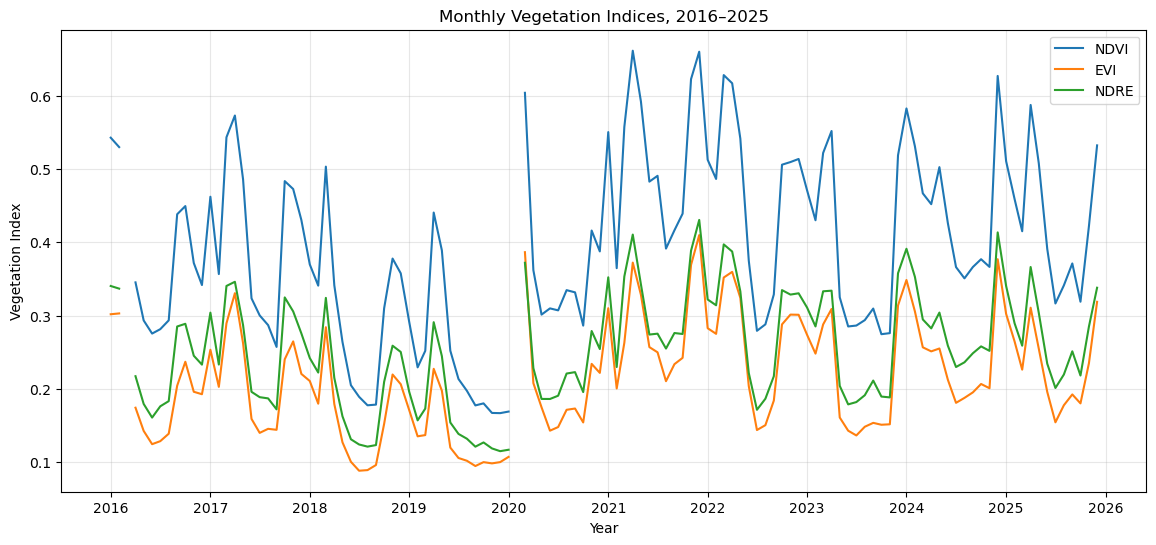

In [22]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_timeseries["date"],
    monthly_timeseries["NDVI"],
    label="NDVI"
)

ax.plot(
    monthly_timeseries["date"],
    monthly_timeseries["EVI"],
    label="EVI"
)

ax.plot(
    monthly_timeseries["date"],
    monthly_timeseries["NDRE"],
    label="NDRE"
)

ax.set_title("Monthly Vegetation Indices, 2016–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Vegetation Index")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

## 13. Sentinel-1 Data Availability

Sentinel-1 SAR data are incorporated to investigate whether radar-derived information provides additional information on rehabilitation trajectories beyond optical vegetation indices.

Available Sentinel-1 observations are first examined across the study period before radar variables are processed and integrated with the Sentinel-2 monthly dataset.

In [23]:
# Search available Sentinel-1 products in DEA

products_df = dc.list_products()

s1_products = products_df[
    products_df["name"]
    .str.contains("s1", case=False, na=False)
]

s1_products[["name", "description"]]

,name,description
name,,
s1_gamma0_geotif_scene,s1_gamma0_geotif_scene,"Sentinel-1A/B SAR Gamma0 scenes, processed to ..."


In [24]:
# Check available Sentinel-1 measurements

s1_measurements = dc.list_measurements()

s1_measurements.loc["s1_gamma0_geotif_scene"]


,name,dtype,units,nodata,aliases,flags_definition
measurement,,,,,,
vh,vh,float32,DN,0,NaN,NaN
vv,vv,float32,DN,0,NaN,NaN


In [25]:
# Check whether Sentinel-1 data exist in DEA during the study period
s1_test = dc.find_datasets(
    product="s1_gamma0_geotif_scene",
    time=("2016-01-01", "2025-12-31")
)

print("Sentinel-1 datasets without spatial filter:", len(s1_test))

if len(s1_test) > 0:
    dates = pd.to_datetime(
        [ds.center_time for ds in s1_test]
    )
    print("First:", dates.min())
    print("Last:", dates.max())

Sentinel-1 datasets without spatial filter: 588
First: 2017-01-01 19:23:36.446879
Last: 2017-12-29 20:40:35.099608


In [26]:
# Check whether available 2017 Sentinel-1 data cover the study area

s1_studyarea = dc.find_datasets(
    product="s1_gamma0_geotif_scene",
    x=x,
    y=y,
    crs="EPSG:7856",
    time=("2017-01-01", "2017-12-31")
)

print("Sentinel-1 observations over study area:", len(s1_studyarea))

Sentinel-1 observations over study area: 0


## 14. Sentinel-1 Monthly Data Import

Monthly Sentinel-1 VV and VH composites processed in Google Earth Engine were exported as annual GeoTIFF files and imported into the DEA Sandbox.

Each annual GeoTIFF contains 24 bands representing monthly VV and VH backscatter from January to December. The data were exported in GDA2020 / MGA Zone 56 (EPSG:7856) at 20 m spatial resolution to facilitate integration with the Sentinel-2 dataset.

In [27]:
# Check exported Sentinel-1 files

from pathlib import Path

s1_folder = Path("Sentinel1")

s1_files = sorted(s1_folder.glob("S1_monthly_*.tif"))

print("Number of Sentinel-1 files:", len(s1_files))

for file in s1_files:
    print(file.name)

Number of Sentinel-1 files: 10
S1_monthly_2016.tif
S1_monthly_2017.tif
S1_monthly_2018.tif
S1_monthly_2019.tif
S1_monthly_2020.tif
S1_monthly_2021.tif
S1_monthly_2022.tif
S1_monthly_2023.tif
S1_monthly_2024.tif
S1_monthly_2025.tif


In [28]:
# Load one annual Sentinel-1 GeoTIFF for inspection

s1_test = rxr.open_rasterio(
    "Sentinel1/S1_monthly_2023.tif"
)

print(s1_test)

<xarray.DataArray (band: 24, y: 324, x: 270)> Size: 17MB
[2099520 values with dtype=float64]
Coordinates:
  * band         (band) int64 192B 1 2 3 4 5 6 7 8 9 ... 17 18 19 20 21 22 23 24
  * x            (x) float64 2kB 3.7e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 3kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('VV_2023_01', 'VH_2023_01', 'VV_2023_02', 'VH_2023_02', ...


In [29]:
# Check spatial properties of the imported Sentinel-1 GeoTIFF

print("Sentinel-1 CRS:")
print(s1_test.rio.crs)

print("\nSentinel-1 resolution:")
print(s1_test.rio.resolution())

print("\nSentinel-1 shape:")
print(s1_test.shape)

print("\nSentinel-1 bounds:")
print(s1_test.rio.bounds())

Sentinel-1 CRS:
EPSG:7856

Sentinel-1 resolution:
(20.0, -20.0)

Sentinel-1 shape:
(24, 324, 270)

Sentinel-1 bounds:
(370040.0, 6977340.0, 375440.0, 6983820.0)


In [30]:
print(
    "Same x coordinates:",
    np.allclose(s1_test.x.values, s2_monthly_all.x.values)
)

print(
    "Same y coordinates:",
    np.allclose(s1_test.y.values, s2_monthly_all.y.values)
)

Same x coordinates: True
Same y coordinates: True


### 15. Load all Sentinel-1 GeoTIFFs
 The Sentinel-1 monthly composites were exported from Google Earth
 Engine as one GeoTIFF per year from 2016 to 2025.

 Each annual GeoTIFF contains 24 bands:
   12 months × 2 SAR variables (VV and VH)

 The band order is:
   VV_YYYY_01, VH_YYYY_01,
   VV_YYYY_02, VH_YYYY_02,
   ...
   VV_YYYY_12, VH_YYYY_12

 This step converts the annual multi-band GeoTIFF files into a
 continuous monthly xarray Dataset with dimensions:

   time × y × x

 and two data variables:

   VV
   VH

In [31]:
from pathlib import Path


# Define the folder containing the Sentinel-1 GeoTIFF files.
s1_folder = Path("Sentinel1")

# Find and sort all annual files from 2016 to 2025.
s1_files = sorted(
    s1_folder.glob("S1_monthly_*.tif")
)

print("Number of Sentinel-1 files:", len(s1_files))

Number of Sentinel-1 files: 10


### Convert annual GeoTIFF bands into monthly VV and VH datasets

In [32]:
# An empty list is created to store the monthly datasets
# generated from each annual GeoTIFF.
s1_yearly_datasets = []


# Loop through all Sentinel-1 annual files.
for file in s1_files:

    # Extract the year from the file name.
    #
    # Example:
    # S1_monthly_2023.tif -> 2023
    year = int(file.stem.split("_")[-1])

    print("Processing:", year)


    # Open the annual 24-band GeoTIFF.
    da = rxr.open_rasterio(file)


    # Separate alternating bands into VV and VH.
    #
    # Python uses zero-based indexing:
    #
    # 0, 2, 4, ... 22 = VV
    # 1, 3, 5, ... 23 = VH
    vv = da.isel(
        band=slice(0, 24, 2)
    )

    vh = da.isel(
        band=slice(1, 24, 2)
    )


    # Create 12 monthly timestamps for the current year.
    #
    # For example, for 2023:
    #
    # 2023-01-01
    # 2023-02-01
    # ...
    # 2023-12-01
    dates = pd.date_range(
        start=f"{year}-01-01",
        periods=12,
        freq="MS"
    )


    # Replace the original GeoTIFF band dimension with
    # the monthly time dimension.
    vv = (
        vv
        .rename({"band": "time"})
        .assign_coords(time=dates)
    )

    vh = (
        vh
        .rename({"band": "time"})
        .assign_coords(time=dates)
    )


    # Combine VV and VH into one xarray Dataset.
    yearly_ds = xr.Dataset({
        "VV": vv,
        "VH": vh
    })


    # Store this year's dataset.
    s1_yearly_datasets.append(yearly_ds)

Processing: 2016
Processing: 2017
Processing: 2018
Processing: 2019
Processing: 2020
Processing: 2021
Processing: 2022
Processing: 2023
Processing: 2024
Processing: 2025


### Combine all years into one continuous Sentinel-1 dataset

In [33]:
# Concatenate the ten annual datasets along the time dimension.
s1_monthly_all = xr.concat(
    s1_yearly_datasets,
    dim="time"
)


# Sort chronologically to ensure that the final time series
# runs continuously from January 2016 to December 2025.
s1_monthly_all = s1_monthly_all.sortby("time")


print(s1_monthly_all)

<xarray.Dataset> Size: 168MB
Dimensions:      (time: 120, y: 324, x: 270)
Coordinates:
  * x            (x) float64 2kB 3.7e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 3kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
    spatial_ref  int64 8B 0
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
Data variables:
    VV           (time, y, x) float64 84MB nan nan nan nan ... nan nan nan nan
    VH           (time, y, x) float64 84MB nan nan nan nan ... nan nan nan nan


### Verify the known missing Sentinel-1 month

In [34]:
jan_2024 = s1_monthly_all.sel(
    time="2024-01-01"
)

print(
    "Valid VV pixels in January 2024:",
    jan_2024.VV.count().item()
)

print(
    "Valid VH pixels in January 2024:",
    jan_2024.VH.count().item()
)

Valid VV pixels in January 2024: 0
Valid VH pixels in January 2024: 0


### Compare Sentinel-1 and Sentinel-2 dataset structures

In [35]:
print("Sentinel-1:")
print(s1_monthly_all.sizes)

print("\nSentinel-2:")
print(s2_monthly_all.sizes)

print(
    "\nSame time coordinates:",
    np.array_equal(
        s1_monthly_all.time.values,
        s2_monthly_all.time.values
    )
)

Sentinel-1:
Frozen({'time': 120, 'y': 324, 'x': 270})

Sentinel-2:
Frozen({'time': 120, 'y': 324, 'x': 270})

Same time coordinates: True


### 16. Merge Sentinel-2 vegetation indices and Sentinel-1 SAR data
Sentinel-1 and Sentinel-2 have now been confirmed to share:
   - the same CRS (EPSG:7856)
   - the same 20 m spatial resolution
   - the same x and y coordinates
   - the same 120 monthly timestamps

 Therefore, the two datasets can be directly merged without
 reprojection, resampling or temporal interpolation.

In [36]:
# Select the vegetation indices required from Sentinel-2.
s2_variables = s2_monthly_all[
    ["NDVI", "EVI", "NDRE"]
]

# Select the SAR variables required from Sentinel-1.
s1_variables = s1_monthly_all[
    ["VV", "VH"]
]

# Remove the duplicate Sentinel-1 spatial reference metadata.
# Sentinel-2 spatial_ref will be retained in the combined dataset.
if "spatial_ref" in s1_variables:
    s1_variables = s1_variables.drop_vars("spatial_ref")

# Merge optical and SAR variables into one monthly dataset.
combined_monthly = xr.merge([
    s2_variables,
    s1_variables
])


print(combined_monthly)

<xarray.Dataset> Size: 294MB
Dimensions:      (time: 120, y: 324, x: 270)
Coordinates:
  * y            (y) float64 3kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 2kB 3.7e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
    spatial_ref  int32 4B 7856
Data variables:
    NDVI         (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan
    EVI          (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan
    NDRE         (time, y, x) float32 42MB nan nan nan nan ... nan nan nan nan
    VV           (time, y, x) float64 84MB nan nan nan nan ... nan nan nan nan
    VH           (time, y, x) float64 84MB nan nan nan nan ... nan nan nan nan


In [37]:
# A month is classified as completely missing when the variable
# contains no valid pixels anywhere within the study area.
#
# This check is performed before machine-learning preparation so
# that temporal gaps from Sentinel-1 and Sentinel-2 are clearly
# documented.

variables = ["NDVI", "EVI", "NDRE", "VV", "VH"]

for variable in variables:

    missing_dates = []

    for date in combined_monthly.time.values:

        monthly_data = combined_monthly[
            variable
        ].sel(time=date)

        # If no valid pixels exist in the entire monthly raster,
        # record the month as completely missing.
        if monthly_data.count().item() == 0:

            missing_dates.append(
                pd.Timestamp(date).strftime("%Y-%m")
            )

    print(
        f"{variable}: "
        f"{len(missing_dates)} completely missing months"
    )

    print(
        "Missing dates:",
        missing_dates
    )

    print()

NDVI: 2 completely missing months
Missing dates: ['2016-03', '2020-02']

EVI: 2 completely missing months
Missing dates: ['2016-03', '2020-02']

NDRE: 2 completely missing months
Missing dates: ['2016-03', '2020-02']

VV: 1 completely missing months
Missing dates: ['2024-01']

VH: 1 completely missing months
Missing dates: ['2024-01']



### Check completely missing months for each variable

## 17. Fractional Vegetation Cover Target

Fractional vegetation cover (FVC) is used as the prediction target to represent vegetation recovery within the rehabilitated mine landscape.

Available fractional cover products in the DEA catalogue are first examined before constructing the 1-year and 5-year prediction targets.

In [38]:
# Search available Fractional Cover products in DEA

products_df = dc.list_products()

fc_products = products_df[
    products_df["name"].str.contains(
        "fractional|fc",
        case=False,
        na=False
    )
]

fc_products[["name", "description"]]

,name,description
name,,
fc_percentile_albers_annual,fc_percentile_albers_annual,"Landsat Fractional Cover percentile 25 metre, ..."
fc_percentile_albers_seasonal,fc_percentile_albers_seasonal,"Landsat Fractional Cover percentile 25 metre, ..."
ga_ls_fc_3,ga_ls_fc_3,Geoscience Australia Landsat Fractional Cover ...
ga_ls_fc_pc_cyear_3,ga_ls_fc_pc_cyear_3,Geoscience Australia Landsat Fractional Cover ...
ls5_fc_albers,ls5_fc_albers,"Landsat 5 Fractional Cover 25 metre, 100km til..."
ls7_fc_albers,ls7_fc_albers,"Landsat 7 Fractional Cover 25 metre, 100km til..."
ls8_fc_albers,ls8_fc_albers,"Landsat 8 Fractional Cover 25 metre, 100km til..."


### Inspect Fractional Cover measurements

In [39]:
measurements_df = dc.list_measurements()

measurements_df.loc["ga_ls_fc_3"]

,name,dtype,units,nodata,aliases,flags_definition
measurement,,,,,,
bs,bs,uint8,percent,255,[bare],NaN
pv,pv,uint8,percent,255,[green_veg],NaN
npv,npv,uint8,percent,255,[dead_veg],NaN
ue,ue,uint8,1,255,[err],NaN


### Check temporal availability of Landsat Fractional Cover

In [40]:
# ------------------------------------------------------------
# Convert study area to the native CRS of Fractional Cover
# ------------------------------------------------------------

# The Fractional Cover product uses Australian Albers (EPSG:3577).
# Reproject the study area from EPSG:7856 to EPSG:3577.
study_area_fc = study_area.to_crs("EPSG:3577")

# Get the bounding coordinates in the FC product CRS.
xmin_fc, ymin_fc, xmax_fc, ymax_fc = study_area_fc.total_bounds

x_fc = (xmin_fc, xmax_fc)
y_fc = (ymin_fc, ymax_fc)

print("Study area CRS:", study_area_fc.crs)
print("X range:", x_fc)
print("Y range:", y_fc)

Study area CRS: EPSG:3577
X range: (np.float64(1917074.7390524987), np.float64(1922827.6882113803))
Y range: (np.float64(-3111594.08545088), np.float64(-3104486.4719073107))


In [41]:
# ------------------------------------------------------------
# Check temporal availability of Fractional Cover
# ------------------------------------------------------------

fc_datasets = dc.find_datasets(
    product="ga_ls_fc_3",
    x=x_fc,
    y=y_fc,
    time=("2016-01-01", "2026-12-31")
)

print("Number of Fractional Cover observations:", len(fc_datasets))

if len(fc_datasets) > 0:
    fc_dates = sorted([
        ds.time.begin
        for ds in fc_datasets
    ])

    print("First observation:", fc_dates[0])
    print("Last observation:", fc_dates[-1])

else:
    print("No Fractional Cover datasets found.")

Number of Fractional Cover observations: 0
No Fractional Cover datasets found.


In [42]:
# ------------------------------------------------------------
# Check whether ga_ls_fc_3 contains datasets for 2016–2025
# without applying any spatial filter
# ------------------------------------------------------------

fc_all = dc.find_datasets(
    product="ga_ls_fc_3",
    time=("2016-01-01", "2025-12-31")
)

print("Total FC datasets in 2016–2025:", len(fc_all))

if len(fc_all) > 0:
    fc_all_dates = sorted([ds.time.begin for ds in fc_all])

    print("First observation:", fc_all_dates[0])
    print("Last observation:", fc_all_dates[-1])

Total FC datasets in 2016–2025: 202206
First observation: 2016-01-01 00:18:47.078666+00:00
Last observation: 2025-12-31 23:53:03.280505+00:00


### Test loading Landsat Fractional Cover for the study area

In [43]:
fc_test = dc.load(
    product="ga_ls_fc_3",

    # Fractional Cover components
    measurements=["pv", "npv", "bs"],

    # Study area coordinates are in EPSG:7856
    x=x,
    y=y,
    crs="EPSG:7856",

    # Test one year first
    time=("2023-01-01", "2023-12-31"),

    # Output in the same CRS as the S1/S2 datasets
    output_crs="EPSG:7856",

    # Keep approximately the native FC resolution
    resolution=(-30, 30),

    group_by="solar_day"
)

print(fc_test)

<xarray.Dataset> Size: 5MB
Dimensions:      (time: 45, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 360B 2023-01-08T23:48:41.579813 ... 20...
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
    spatial_ref  int32 4B 7856
Data variables:
    pv           (time, y, x) uint8 2MB 18 18 23 21 23 29 ... 45 48 48 39 39 38
    npv          (time, y, x) uint8 2MB 74 78 51 67 63 48 ... 52 48 49 44 17 21
    bs           (time, y, x) uint8 2MB 8 3 25 11 13 22 7 2 ... 2 2 2 2 16 43 40
Attributes:
    crs:           EPSG:7856
    grid_mapping:  spatial_ref


### Quality check for Landsat Fractional Cover

In [44]:
import numpy as np

for var in ["pv", "npv", "bs"]:

    data = fc_test[var]

    # Count NoData pixels (255)
    nodata_count = int((data == 255).sum())

    # Keep only valid fractional cover values (0–100%)
    valid = data.where(data <= 100)

    print(f"{var.upper()}:")
    print("  Minimum:", float(valid.min()))
    print("  Maximum:", float(valid.max()))
    print("  NoData pixels:", nodata_count)
# Check whether PV + NPV + BS is approximately 100%
fc_sum = (
    fc_test["pv"].where(fc_test["pv"] <= 100) +
    fc_test["npv"].where(fc_test["npv"] <= 100) +
    fc_test["bs"].where(fc_test["bs"] <= 100)
)

print("FC sum minimum:", float(fc_sum.min()))
print("FC sum maximum:", float(fc_sum.max()))
print("FC sum mean:", float(fc_sum.mean()))

PV:
  Minimum: 2.0
  Maximum: 100.0
  NoData pixels: 0
NPV:
  Minimum: 0.0
  Maximum: 100.0
  NoData pixels: 0
BS:
  Minimum: 2.0
  Maximum: 98.0
  NoData pixels: 0
FC sum minimum: 4.0
FC sum maximum: 138.0
FC sum mean: 96.84137725830078


### Reload Fractional Cover including unmixing error (UE)

In [45]:
fc_test = dc.load(
    product="ga_ls_fc_3",
    measurements=["pv", "npv", "bs", "ue"],
    x=x,
    y=y,
    crs="EPSG:7856",
    time=("2023-01-01", "2023-12-31"),
    output_crs="EPSG:7856",
    resolution=(-30, 30),
    group_by="solar_day"
)

print(fc_test)

<xarray.Dataset> Size: 7MB
Dimensions:      (time: 45, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 360B 2023-01-08T23:48:41.579813 ... 20...
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
    spatial_ref  int32 4B 7856
Data variables:
    pv           (time, y, x) uint8 2MB 18 18 23 21 23 29 ... 45 48 48 39 39 38
    npv          (time, y, x) uint8 2MB 74 78 51 67 63 48 ... 52 48 49 44 17 21
    bs           (time, y, x) uint8 2MB 8 3 25 11 13 22 7 2 ... 2 2 2 2 16 43 40
    ue           (time, y, x) uint8 2MB 4 4 6 6 6 10 10 ... 29 31 32 26 16 10 8
Attributes:
    crs:           EPSG:7856
    grid_mapping:  spatial_ref


### Examine total vegetation cover (PV + NPV)

In [46]:
# Convert FC components to float so invalid values can be
# represented as NaN if required later.
pv = fc_test["pv"].astype("float32")
npv = fc_test["npv"].astype("float32")

# Calculate total fractional vegetation cover
fvc_raw = pv + npv

# Basic statistics
print("Raw FVC minimum:", float(fvc_raw.min()))
print("Raw FVC maximum:", float(fvc_raw.max()))
print("Raw FVC mean:", float(fvc_raw.mean()))

# Check how often FVC exceeds 100%
n_total = int(fvc_raw.count())
n_over100 = int((fvc_raw > 100).sum())

print("Total pixels:", n_total)
print("Pixels with FVC > 100%:", n_over100)
print(
    "Percentage > 100%:",
    round(n_over100 / n_total * 100, 3),
    "%"
)

Raw FVC minimum: 2.0
Raw FVC maximum: 136.0
Raw FVC mean: 84.54081726074219
Total pixels: 1749600
Pixels with FVC > 100%: 16393
Percentage > 100%: 0.937 %


### Examine unmixing error for FVC values above 100%

In [47]:
pv = fc_test["pv"].astype("float32")
npv = fc_test["npv"].astype("float32")
ue = fc_test["ue"].astype("float32")

fvc_raw = pv + npv

# UE statistics for all pixels
print("Mean UE - all pixels:",
      float(ue.mean()))

# UE statistics where FVC <= 100%
print("Mean UE - FVC <= 100%:",
      float(ue.where(fvc_raw <= 100).mean()))

# UE statistics where FVC > 100%
print("Mean UE - FVC > 100%:",
      float(ue.where(fvc_raw > 100).mean()))

Mean UE - all pixels: 11.98206901550293
Mean UE - FVC <= 100%: 11.619096755981445
Mean UE - FVC > 100%: 50.106204986572266


### Create quality-controlled Fractional Vegetation Cover (FVC)

In [48]:
# Convert fractional cover components to float
pv = fc_test["pv"].astype("float32")
npv = fc_test["npv"].astype("float32")

# Total vegetation cover:
# photosynthetic vegetation + non-photosynthetic vegetation
fvc = pv + npv

# Remove physically invalid estimates above 100%
fvc = fvc.where(
    (fvc >= 0) & (fvc <= 100)
)

# Add FVC to the dataset
fc_test["FVC"] = fvc

print("FVC minimum:", float(fvc.min()))
print("FVC maximum:", float(fvc.max()))
print("FVC mean:", float(fvc.mean()))

FVC minimum: 2.0
FVC maximum: 100.0
FVC mean: 84.34674072265625


### Create monthly FVC composites

In [49]:
fvc_monthly_2023 = (
    fc_test[["FVC"]]
    .resample(time="1MS")
    .median()
)

print(fvc_monthly_2023)

<xarray.Dataset> Size: 2MB
Dimensions:      (time: 12, y: 216, x: 180)
Coordinates:
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
    spatial_ref  int32 4B 7856
  * time         (time) datetime64[ns] 96B 2023-01-01 2023-02-01 ... 2023-12-01
Data variables:
    FVC          (time, y, x) float32 2MB 89.0 89.0 74.0 87.0 ... 88.0 87.0 91.0
Attributes:
    crs:           EPSG:7856
    grid_mapping:  spatial_ref


### Check monthly FVC data availability

In [50]:
for t in fvc_monthly_2023.time.values:

    month_data = fvc_monthly_2023["FVC"].sel(time=t)

    valid_pixels = int(month_data.count())
    total_pixels = month_data.size

    coverage = valid_pixels / total_pixels * 100

    print(
        pd.Timestamp(t).strftime("%Y-%m"),
        f"{coverage:.2f}%"
    )

2023-01 100.00%
2023-02 100.00%
2023-03 100.00%
2023-04 100.00%
2023-05 99.25%
2023-06 98.89%
2023-07 100.00%
2023-08 100.00%
2023-09 99.77%
2023-10 99.94%
2023-11 100.00%
2023-12 99.86%


## 18. Monthly Fractional Vegetation Cover (2016–2025)

Landsat Fractional Cover was used to derive total fractional vegetation cover (FVC) as the sum of photosynthetic vegetation (PV) and non-photosynthetic vegetation (NPV).

FVC estimates outside the physically meaningful range of 0–100% were excluded. Valid observations were aggregated into monthly median composites for subsequent vegetation recovery prediction.

### Generate monthly FVC composites for 2016–2025

In [51]:
fvc_yearly = []

for year in range(2016, 2026):

    print(f"Processing {year}...")

    # Load Landsat Fractional Cover for one year
    fc = dc.load(
        product="ga_ls_fc_3",
        measurements=["pv", "npv"],
        x=x,
        y=y,
        crs="EPSG:7856",
        time=(f"{year}-01-01", f"{year}-12-31"),
        output_crs="EPSG:7856",
        resolution=(-30, 30),
        group_by="solar_day"
    )

    # Convert to float
    pv = fc["pv"].astype("float32")
    npv = fc["npv"].astype("float32")

    # Calculate total fractional vegetation cover
    fvc = pv + npv

    # Remove physically invalid estimates
    fvc = fvc.where(
        (fvc >= 0) & (fvc <= 100)
    )

    # Convert individual observations to monthly median composites
    fvc_monthly = (
        fvc
        .resample(time="1MS")
        .median()
        .to_dataset(name="FVC")
    )

    fvc_yearly.append(fvc_monthly)

    print(
        f"  Observations: {fc.sizes.get('time', 0)}, "
        f"monthly composites: {fvc_monthly.sizes.get('time', 0)}"
    )

# Combine all years into one continuous time series
fvc_monthly_all = xr.concat(
    fvc_yearly,
    dim="time"
).sortby("time")

print("\nFinal FVC dataset:")
print(fvc_monthly_all)

Processing 2016...
  Observations: 43, monthly composites: 12
Processing 2017...
  Observations: 43, monthly composites: 12
Processing 2018...
  Observations: 43, monthly composites: 12
Processing 2019...
  Observations: 44, monthly composites: 12
Processing 2020...
  Observations: 42, monthly composites: 12
Processing 2021...
  Observations: 43, monthly composites: 12
Processing 2022...
  Observations: 46, monthly composites: 12
Processing 2023...
  Observations: 45, monthly composites: 12
Processing 2024...
  Observations: 45, monthly composites: 12
Processing 2025...
  Observations: 45, monthly composites: 12

Final FVC dataset:
<xarray.Dataset> Size: 19MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
    spatial_ref  int32 4B 7856
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
Data var

### Compare S1/S2 and FVC spatial grids

In [52]:
print("S1/S2 grid:")
print("  Shape:",
      combined_monthly.sizes["y"],
      "x",
      combined_monthly.sizes["x"])

print("  X range:",
      float(combined_monthly.x.min()),
      "to",
      float(combined_monthly.x.max()))

print("  Y range:",
      float(combined_monthly.y.min()),
      "to",
      float(combined_monthly.y.max()))


print("\nFVC grid:")
print("  Shape:",
      fvc_monthly_all.sizes["y"],
      "x",
      fvc_monthly_all.sizes["x"])

print("  X range:",
      float(fvc_monthly_all.x.min()),
      "to",
      float(fvc_monthly_all.x.max()))

print("  Y range:",
      float(fvc_monthly_all.y.min()),
      "to",
      float(fvc_monthly_all.y.max()))


print("\nTemporal alignment:")
print(
    "Same time coordinates:",
    np.array_equal(
        combined_monthly.time.values,
        fvc_monthly_all.time.values
    )
)

S1/S2 grid:
  Shape: 324 x 270
  X range: 370050.0 to 375430.0
  Y range: 6977350.0 to 6983810.0

FVC grid:
  Shape: 216 x 180
  X range: 370065.0 to 375435.0
  Y range: 6977355.0 to 6983805.0

Temporal alignment:
Same time coordinates: True


### Resample S1/S2 predictors to the 30 m FVC grid

In [53]:
import rioxarray

from rasterio.enums import Resampling

# Use one FVC layer as the target spatial grid
fvc_template = fvc_monthly_all["FVC"].isel(time=0)

# Ensure CRS information is explicitly available to rioxarray
predictors_20m = combined_monthly[
    ["NDVI", "EVI", "NDRE", "VV", "VH"]
].rio.write_crs("EPSG:7856")

fvc_template = fvc_template.rio.write_crs("EPSG:7856")

# Reproject/resample all predictors to exactly match
# the 30 m Fractional Cover grid.
predictors_30m = predictors_20m.rio.reproject_match(
    fvc_template,
    resampling=Resampling.bilinear
)

print(predictors_30m)

<xarray.Dataset> Size: 131MB
Dimensions:      (time: 120, x: 180, y: 216)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
    spatial_ref  int64 8B 0
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
Data variables:
    NDVI         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    EVI          (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    NDRE         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    VV           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan
    VH           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan


### Verify spatial alignment with the FVC target

In [54]:
print("Predictor shape:",
      predictors_30m.sizes["y"],
      "x",
      predictors_30m.sizes["x"])

print("FVC shape:",
      fvc_monthly_all.sizes["y"],
      "x",
      fvc_monthly_all.sizes["x"])

print(
    "Same X coordinates:",
    np.allclose(
        predictors_30m.x.values,
        fvc_monthly_all.x.values
    )
)

print(
    "Same Y coordinates:",
    np.allclose(
        predictors_30m.y.values,
        fvc_monthly_all.y.values
    )
)

print(
    "Same time coordinates:",
    np.array_equal(
        predictors_30m.time.values,
        fvc_monthly_all.time.values
    )
)

Predictor shape: 216 x 180
FVC shape: 216 x 180
Same X coordinates: True
Same Y coordinates: True
Same time coordinates: True


### Combine predictors and FVC target

In [56]:
# Select predictor variables
predictors_final = predictors_30m[
    ["NDVI", "EVI", "NDRE", "VV", "VH"]
]

# Remove the duplicate spatial_ref metadata from predictors.
# Both datasets have already been aligned to the same
# EPSG:7856 spatial grid.
if "spatial_ref" in predictors_final.coords:
    predictors_final = predictors_final.drop_vars("spatial_ref")
    
# Merge predictors with the FVC target
model_data = xr.merge([
    predictors_final,
    fvc_monthly_all[["FVC"]]
])

print(model_data)

<xarray.Dataset> Size: 149MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
    spatial_ref  int32 4B 7856
Data variables:
    NDVI         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    EVI          (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    NDRE         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    VV           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan
    VH           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan
    FVC          (time, y, x) float32 19MB 92.0 93.0 92.0 ... 86.0 90.0 91.0


### Final monthly data availability check

In [57]:
for var in ["NDVI", "EVI", "NDRE", "VV", "VH", "FVC"]:

    missing_months = []

    for t in model_data.time.values:

        data = model_data[var].sel(time=t)

        if int(data.count()) == 0:
            missing_months.append(
                pd.Timestamp(t).strftime("%Y-%m")
            )

    print(
        f"{var}: {len(missing_months)} completely missing months"
    )
    print(missing_months)

NDVI: 2 completely missing months
['2016-03', '2020-02']
EVI: 2 completely missing months
['2016-03', '2020-02']
NDRE: 2 completely missing months
['2016-03', '2020-02']
VV: 1 completely missing months
['2024-01']
VH: 1 completely missing months
['2024-01']
FVC: 0 completely missing months
[]


### Save final preprocessed dataset for ML modelling

In [59]:
output_file = "model_data_2016_2025.nc"

# Make a copy for saving
model_data_save = model_data.copy()

# Remove inherited time metadata that conflicts with NetCDF CF time encoding
model_data_save["time"].attrs.pop("units", None)
model_data_save["time"].attrs.pop("calendar", None)

# Save to NetCDF
model_data_save.to_netcdf(output_file)

print(f"Saved successfully: {output_file}")

Saved successfully: model_data_2016_2025.nc


# ------------------------------------------------------------
### Verify the saved NetCDF file

In [60]:
test_load = xr.open_dataset(
    "model_data_2016_2025.nc"
)

print(test_load)

print(
    "Time range:",
    test_load.time.values[0],
    "to",
    test_load.time.values[-1]
)

<xarray.Dataset> Size: 149MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
Data variables:
    NDVI         (time, y, x) float32 19MB ...
    EVI          (time, y, x) float32 19MB ...
    NDRE         (time, y, x) float32 19MB ...
    VV           (time, y, x) float64 37MB ...
    VH           (time, y, x) float64 37MB ...
    FVC          (time, y, x) float32 19MB ...
    spatial_ref  int32 4B ...
Time range: 2016-01-01T00:00:00.000000000 to 2025-12-01T00:00:00.000000000
